# ST1131 Introduction to Statistics and Statistical Computing
## Topic 9 (Linear Regression)

In the lecture, we learnt how a linear regression model uses explanatory variables to estimate the mean of a response variable, how the coefficients are estimated by ordinary least squares (OLS), how to test and check a fitted model, and how to extend it with more regressors, categorical variables, interaction terms, higher-order terms and transformations. In this notebook, we will fit and check all of these models in Python using the Selling Price of Old Cars dataset from the lecture.

The general workflow for a regression analysis is:

1. Plot the data
2. Fit the model
3. Test the model and its coefficients
4. Check the assumptions using residual plots
5. Interpret the model, or modify it if the assumptions do not hold

## Packages

Besides the packages from previous topics, we now use `statsmodels`, a package for fitting statistical models. We import its formula interface as `smf`, which lets us describe a model in words, such as `"Selling_Price ~ Present_Price"`. If `statsmodels` is not installed in your environment yet, run `pip install statsmodels` in the terminal first.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, t, probplot
import statsmodels.formula.api as smf

As in Topics 7 and 8, we must not create a variable called `t`, since that would replace the $t$-distribution.

## The Selling Price of Old Cars dataset

The goal is to predict the response `Selling_Price` of a used car (in thousands of dollars) from one or more explanatory variables. The main ones we use are `Present_Price` (the price of a brand new car of the same model, in thousands of dollars), `Kms_Driven`, `Fuel_Type` (CNG, Diesel or Petrol) and `Transmission` (Automatic or Manual).

In [3]:
cars = pd.read_csv("../data/oldcars.csv")
print(cars.shape)
print(cars[["Selling_Price", "Present_Price", "Kms_Driven", "Fuel_Type", "Transmission"]].head())

(301, 9)
   Selling_Price  Present_Price  Kms_Driven Fuel_Type Transmission
0           3.35           5.59       27000    Petrol       Manual
1           4.75           9.54       43000    Diesel       Manual
2           7.25           9.85        6900    Petrol       Manual
3           2.85           4.15        5200    Petrol       Manual
4           4.60           6.87       42450    Diesel       Manual


### Plotting the data first

Before fitting a model, we plot the response against the regressor and compute the correlation coefficient, as in Topic 2.

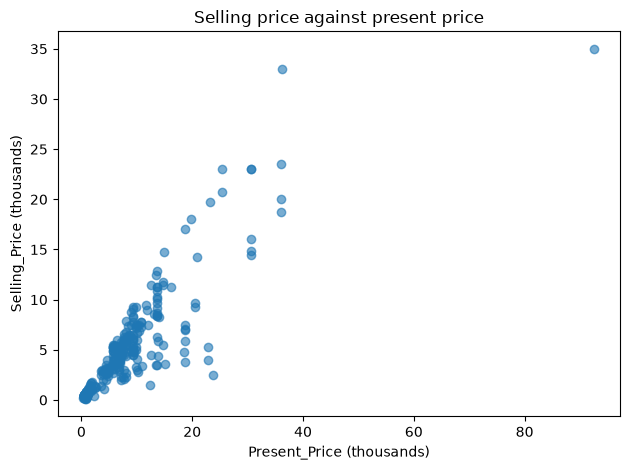

Correlation: 0.88


In [4]:
plt.figure()
plt.scatter(cars["Present_Price"], cars["Selling_Price"], color="tab:blue", alpha=0.6)
plt.xlabel("Present_Price (thousands)")
plt.ylabel("Selling_Price (thousands)")
plt.title("Selling price against present price")
plt.tight_layout()
plt.show()

print(f"Correlation: {round(cars['Present_Price'].corr(cars['Selling_Price']), 2)}")

The relationship looks roughly linear, with a strong positive correlation of 0.88. Notice that the points spread out more as `Present_Price` increases, which we will come back to when checking the assumptions.

## Simple linear regression

The simple linear regression model is $Y=\beta_0+\beta_1X+\varepsilon$. With `smf.ols`, we write the model as a formula with the response on the left of `~` and the regressor on the right. The intercept is included automatically. Calling `.fit()` estimates the coefficients by OLS.

In [5]:
model = smf.ols("Selling_Price ~ Present_Price", data=cars).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          Selling_Price   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.772
Method:                 Least Squares   F-statistic:                     1016.
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           3.60e-98
Time:                        00:47:31   Log-Likelihood:                -693.08
No. Observations:                 301   AIC:                             1390.
Df Residuals:                     299   BIC:                             1398.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         0.7185      0.187      3.847

The summary contains everything in the lecture's regression output, although it is arranged differently. The values we need most often can be pulled out directly:

| What | Code |
|---|---|
| Coefficient estimates $\hat{\beta}_0,\hat{\beta}_1$ | `model.params` |
| Standard errors | `model.bse` |
| $t$ values and $p$-values | `model.tvalues`, `model.pvalues` |
| $R^2$ and adjusted $R^2$ | `model.rsquared`, `model.rsquared_adj` |
| $F$-statistic and its $p$-value | `model.fvalue`, `model.f_pvalue` |

In [6]:
print(model.params)
print(model.bse)

Intercept        0.718527
Present_Price    0.516849
dtype: float64
Intercept        0.186773
Present_Price    0.016216
dtype: float64


So the fitted equation is $\hat{Y}=0.72+0.52X$. For each \$1000 increase in `Present_Price`, the average `Selling_Price` is estimated to increase by 0.52 thousand dollars (\$520).

We can access a single coefficient by its name.

In [7]:
b0 = model.params["Intercept"]
b1 = model.params["Present_Price"]
print(f"Fitted equation: Y-hat = {round(b0, 2)} + {round(b1, 2)}X")

Fitted equation: Y-hat = 0.72 + 0.52X


### Ordinary least squares

OLS picks the line that minimises the sum of squared residuals (SSR), $\sum e_i^2$ where $e_i=y_i-\hat{y}_i$. To see this, let's compare the SSR of the fitted line with two other candidate lines.

In [8]:
x = cars["Present_Price"]
y = cars["Selling_Price"]

for name, a, b in [("Fitted line", b0, b1), ("Candidate 1", 0, 0.5), ("Candidate 2", 1, 0.55)]:
    residuals = y-(a+b*x)
    print(f"{name}: SSR = {round(np.sum(residuals**2), 2)}")

Fitted line: SSR = 1762.38
Candidate 1: SSR = 1984.72
Candidate 2: SSR = 1872.97


The fitted line has the smallest SSR, and no other line can do better. Solving for the minimum gives the formulas

$$\hat{\beta}_1=\frac{\sum(x_i-\bar{x})(y_i-\bar{y})}{\sum(x_i-\bar{x})^2},\qquad\hat{\beta}_0=\bar{y}-\hat{\beta}_1\bar{x},$$

which give exactly the same estimates.

In [9]:
b1_formula = np.sum((x-np.mean(x))*(y-np.mean(y)))/np.sum((x-np.mean(x))**2)
b0_formula = np.mean(y)-b1_formula*np.mean(x)
print(f"By formula: b0 = {round(b0_formula, 5)}, b1 = {round(b1_formula, 5)}")

By formula: b0 = 0.71853, b1 = 0.51685


## Estimating the mean response

`model.predict` gives the point estimate $\hat{Y}$ for new values of $X$. The new values must be given as a DataFrame with the same column name as in the formula.

In [10]:
new_cars = pd.DataFrame({"Present_Price": [20, 40]})
print(model.predict(new_cars))

0    11.055508
1    21.392489
dtype: float64


If we use the rounded coefficients of 0.72 and 0.52, our estimates are 11.12 and 21.52. Python uses the unrounded estimates, so the answers are 11.06 and 21.39, which are more accurate. You are always expected to be as accurate as possible.

### Interpolation and extrapolation

Both values are inside the observed range of `Present_Price`, so these are interpolations. Estimating outside this range is extrapolation, which we generally avoid.

In [11]:
print(f"Range of Present_Price: {cars['Present_Price'].min()} to {cars['Present_Price'].max()}")

Range of Present_Price: 0.32 to 92.6


### Estimating $\sigma$

The estimate $\hat{\sigma}$, called the residual standard error, measures how far the points typically lie from the fitted line. It is the square root of `model.mse_resid`.

In [12]:
print(f"Residual standard error: {round(np.sqrt(model.mse_resid), 3)}")
print(f"Residual degrees of freedom: {model.df_resid}")

Residual standard error: 2.428
Residual degrees of freedom: 299.0


The residual standard error is $\hat{\sigma} = 2.428$ on $299$ degrees of freedom, since $df=n-2=301-2$.

### Confidence intervals for the coefficients

The $100(1-\alpha)\%$ CI for $\beta_1$ is $\hat{\beta}_1\pm t_{n-2,1-\alpha/2}\times SE(\hat{\beta}_1)$. The function `model.conf_int` gives the CIs for all coefficients at once, and we can check the one for $\beta_1$ with the formula.

In [13]:
print(model.conf_int(alpha=0.05))

t_mult = t.ppf(0.975, df=model.df_resid)
se_b1 = model.bse["Present_Price"]
print(f"95% CI for beta_1 by formula: ({round(b1-t_mult*se_b1, 3)}, {round(b1+t_mult*se_b1, 3)})")

                      0         1
Intercept      0.350972  1.086083
Present_Price  0.484938  0.548760
95% CI for beta_1 by formula: (0.485, 0.549)


The 95% CI for $\beta_1$ is (0.485, 0.549).

### Confidence interval for the mean response

`model.get_prediction(...).summary_frame(alpha=0.05)` gives the CI for the mean response. We keep only the three columns we need.

In [14]:
pred = model.get_prediction(new_cars).summary_frame(alpha=0.05)
print(pred[["mean", "mean_ci_lower", "mean_ci_upper"]])

        mean  mean_ci_lower  mean_ci_upper
0  11.055508      10.574160      11.536856
1  21.392489      20.323398      22.461579


These match the lecture: (10.57, 11.54) when $X=20$ and (20.32, 22.46) when $X=40$. We are 95% confident that the true **average** selling price of all used cars with a present price of 20 thousand lies between 10.57 and 11.54 thousand. Notice that the interval at $X=40$ is wider, since there are fewer cars with such a high present price.

## Hypothesis tests for regression

### $t$-test for $\beta_1$

To test $H_0: \beta_1=0$ against $H_1: \beta_1\neq0$, the test statistic is $t=\hat{\beta}_1/SE(\hat{\beta}_1)$, with null distribution $t_{n-2}$. The summary already gives $t$ and its $p$-value, and we can check them using `t.sf`.

In [15]:
b1 = model.params["Present_Price"]
se_b1 = model.bse["Present_Price"]
T_stat = b1/se_b1
print(f"Test statistic: {round(T_stat, 3)}")
print(f"From the model: {round(model.tvalues['Present_Price'], 3)}")
print(f"p-value: {2*t.sf(abs(T_stat), df=model.df_resid)}")

Test statistic: 31.874
From the model: 31.874
p-value: 3.60218642872724e-98


$t$ is 31.874 and the $p$-value is practically 0, so there is very strong evidence that `Present_Price` is a significant regressor. We will get 31.865 instead from dividing the rounded values 0.51685 and 0.01622.

### $F$-test for the overall model

The $F$-test checks whether the model as a whole is significant. Its null distribution is $F(df_1, df_2)$, where $df_1$ is the number of coefficients excluding the intercept and $df_2=n-(\text{number of coefficients})$.

In [16]:
print(f"F-statistic: {round(model.fvalue, 1)}")
print(f"df1 = {model.df_model}, df2 = {model.df_resid}")
print(f"p-value: {model.f_pvalue}")
print(f"Square of the t statistic: {round(T_stat**2, 1)}")

F-statistic: 1015.9
df1 = 1.0, df2 = 299.0
p-value: 3.6021864287275015e-98
Square of the t statistic: 1015.9


The $F$-statistic is 1016 on 1 and 299 degrees of freedom. In simple linear regression, the $F$-test and the $t$-test for $\beta_1$ are equivalent, and in fact $F=T^2$.

### Intercept-only model

The formula `"Selling_Price ~ 1"` fits a model with only an intercept. Its estimate is just the sample mean $\bar{Y}$, so it predicts the same value whatever $X$ is.

In [17]:
model_0 = smf.ols("Selling_Price ~ 1", data=cars).fit()
print(f"Intercept-only model: {round(model_0.params['Intercept'], 3)}")
print(f"Sample mean of Selling_Price: {round(np.mean(cars['Selling_Price']), 3)}")

Intercept-only model: 4.661
Sample mean of Selling_Price: 4.661


## Coefficient of determination $R^2$

$R^2$ is the proportion of the total variation in the response that is explained by the model. In simple linear regression, $|Cor(X,Y)|=\sqrt{R^2}$.

In [18]:
print(f"R-squared: {round(model.rsquared, 3)}")
print(f"Square root of R-squared: {round(np.sqrt(model.rsquared), 2)}")

R-squared: 0.773
Square root of R-squared: 0.88


77.3% of the variation in `Selling_Price` is explained by the model, and $\sqrt{0.773}=0.88$ is the correlation we found earlier.

## Regression diagnostics

The assumptions of linearity, normality and constant variance are checked with the **standardized residuals** (SR) $r_i$. If the assumptions hold, the SR should scatter randomly about 0, mostly within $(-3,3)$, and follow an approximately normal distribution.

We get the SR, and later Cook's distance, from `model.get_influence()`. The SR are stored in `resid_studentized_internal`, which is the name `statsmodels` uses for we call standardized residuals.

In [19]:
influence = model.get_influence()
sr = influence.resid_studentized_internal #standardized residuals
fitted = model.fittedvalues #Y-hat for each car

print(f"Smallest SR: {round(sr.min(), 2)}, largest SR: {round(sr.max(), 2)}")

Smallest SR: -6.81, largest SR: 5.7


We draw the four residual plots from the lecture in a $2\times2$ grid with `plt.subplots(2, 2)`. Each plot is then `axes[row, column]`. The dashed lines mark 0 and $\pm3$.

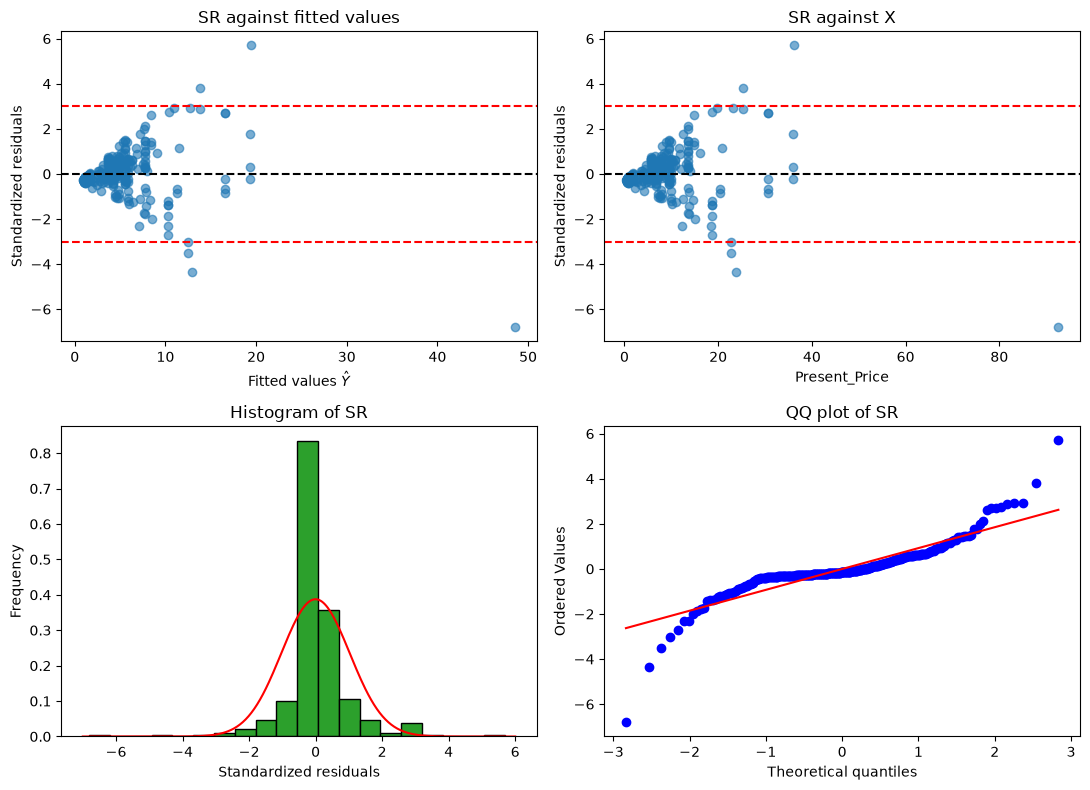

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(11,8))

axes[0, 0].scatter(fitted, sr, color="tab:blue", alpha=0.6)
axes[0, 0].set_xlabel(r"Fitted values $\hat{Y}$")
axes[0, 0].set_title("SR against fitted values")

axes[0, 1].scatter(cars["Present_Price"], sr, color="tab:blue", alpha=0.6)
axes[0, 1].set_xlabel("Present_Price")
axes[0, 1].set_title("SR against X")

for ax in [axes[0, 0], axes[0, 1]]:
    ax.axhline(0, color="black", linestyle="--")
    ax.axhline(3, color="red", linestyle="--")
    ax.axhline(-3, color="red", linestyle="--")
    ax.set_ylabel("Standardized residuals")

axes[1, 0].hist(sr, bins=20, density=True, color="tab:green", edgecolor="black")
x_vals = np.linspace(-7, 6, 301)
y_vals = norm.pdf(x_vals, loc=np.mean(sr), scale=np.std(sr, ddof=1))
axes[1, 0].plot(x_vals, y_vals, color="red")
axes[1, 0].set_xlabel("Standardized residuals")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_title("Histogram of SR")

probplot(sr, plot=axes[1, 1])
axes[1, 1].set_title("QQ plot of SR")

plt.tight_layout()
plt.show()

As in the lecture:

- The SR against $\hat{Y}$ and against $X$ form a clear funnel shape, so the constant variance assumption is violated.
- The SR range from about $-7$ to $6$, with several outside $(-3,3)$.
- The histogram is not symmetric, and the QQ plot deviates from the line in both tails, so the normality assumption is violated.

The model is not adequate, and it should be modified before it is used for inference or prediction.

### Outliers and influential points

An outlier has an SR above 3 or below $-3$. An influential point has a Cook's distance above 1. Cook's distances are stored in `influence.cooks_distance[0]`.

In [21]:
cooks = influence.cooks_distance[0]
cars["SR"] = sr
cars["Cooks"] = cooks

print("Outliers (|SR| > 3):")
print(cars.loc[np.abs(sr) > 3, ["Car_Name", "Present_Price", "Selling_Price", "SR"]].round(2))

print()
print("Influential points (Cook's distance > 1):")
print(cars.loc[cooks > 1, ["Car_Name", "Present_Price", "Selling_Price", "Cooks"]].round(2))

Outliers (|SR| > 3):
         Car_Name  Present_Price  Selling_Price    SR
64       fortuner          36.23          33.00  5.70
78  corolla altis          22.83           5.25 -3.01
82         innova          25.39          23.00  3.81
85          camry          23.73           2.50 -4.35
86   land cruiser          92.60          35.00 -6.81
94  corolla altis          22.78           4.00 -3.52

Influential points (Cook's distance > 1):
        Car_Name  Present_Price  Selling_Price  Cooks
86  land cruiser           92.6           35.0  11.18


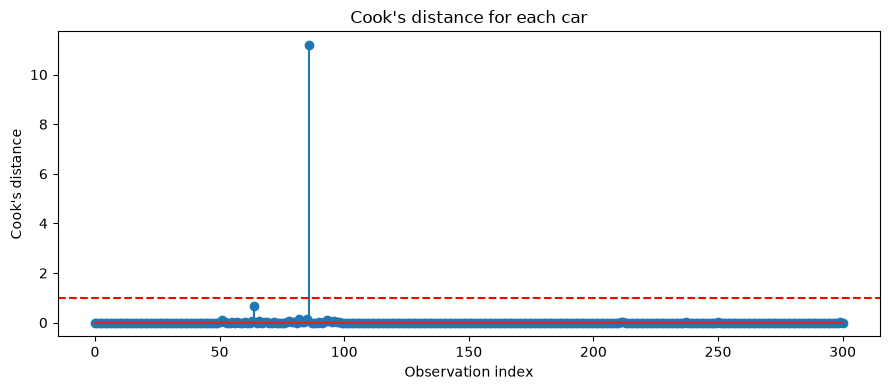

In [22]:
plt.figure(figsize=(9,4))
plt.stem(cars.index, cooks)
plt.axhline(1, color="red", linestyle="--")
plt.xlabel("Observation index")
plt.ylabel("Cook's distance")
plt.title("Cook's distance for each car")
plt.tight_layout()
plt.show()

There are 6 outliers, and one car, the land cruiser at index 86, has a Cook's distance of about 11. Its present price of 92.6 thousand is far larger than any other car's, so it pulls the fitted line strongly towards itself.

## Multiple linear regression

To add more regressors, we join them with `+` in the formula. Let's add `Kms_Driven` to the model:

$$Y=\beta_0+\beta_1(\text{Present\_Price})+\beta_2(\text{Kms\_Driven})+\varepsilon.$$

In [23]:
model_2 = smf.ols("Selling_Price ~ Present_Price + Kms_Driven", data=cars).fit()
print(model_2.summary())

                            OLS Regression Results                            
Dep. Variable:          Selling_Price   R-squared:                       0.796
Model:                            OLS   Adj. R-squared:                  0.795
Method:                 Least Squares   F-statistic:                     581.5
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          1.34e-103
Time:                        00:47:32   Log-Likelihood:                -676.73
No. Observations:                 301   AIC:                             1359.
Df Residuals:                     298   BIC:                             1371.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                    coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------
Intercept         1.3306      0.206      6.466

The fitted model is $\hat{Y}=1.331+0.5356(\text{Present\_Price})-0.00002043(\text{Kms\_Driven})$. Both $p$-values are very small, so both regressors are significant, and the $F$-statistic of 581.5 shows the model is significant.

### Adjusted $R^2$

With more than one regressor, we compare models using adjusted $R^2=1-\frac{(1-R^2)(n-1)}{n-k-1}$, where $k$ is the number of regressors.

In [24]:
n = len(cars)
k = 2
r2 = model_2.rsquared
adj_r2 = 1-(1-r2)*(n-1)/(n-k-1)

print(f"R-squared: {round(r2, 4)}")
print(f"Adjusted R-squared by formula: {round(adj_r2, 4)}")
print(f"Adjusted R-squared from the model: {round(model_2.rsquared_adj, 4)}")
print(f"Adjusted R-squared of the simple model: {round(model.rsquared_adj, 4)}")

R-squared: 0.796
Adjusted R-squared by formula: 0.7947
Adjusted R-squared from the model: 0.7947
Adjusted R-squared of the simple model: 0.7718


The adjusted $R^2$ increases from 0.772 to 0.795, so adding `Kms_Driven` improves the model. 79.5% of the variation in `Selling_Price` is explained by this model.

## Categorical variables and interaction terms

### Indicator variables

Writing `C(Transmission)` in a formula tells `statsmodels` that `Transmission` is categorical, and it creates the indicator variable for us. The first category in alphabetical order, Automatic, becomes the baseline, so the indicator is $I(\text{Transmission}=\text{Manual})$, shown as `C(Transmission)[T.Manual]`.

In [25]:
model_c = smf.ols("Selling_Price ~ Present_Price + C(Transmission)", data=cars).fit()
print(model_c.summary())

                            OLS Regression Results                            
Dep. Variable:          Selling_Price   R-squared:                       0.777
Model:                            OLS   Adj. R-squared:                  0.775
Method:                 Least Squares   F-statistic:                     518.5
Date:                Tue, 20 Oct 2026   Prob (F-statistic):           9.07e-98
Time:                        00:47:32   Log-Likelihood:                -690.29
No. Observations:                 301   AIC:                             1387.
Df Residuals:                     298   BIC:                             1398.
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                                coef    std err          t      P>|t|      [0.025      0.975]
---------------------------------------------------------------------------------------------
Intercept             

In this case, the fitted model is $\hat{Y}=1.7209+0.5027(\text{Present\_Price})-1.0315 I(X_2=\text{Manual})$.

First, we plot the data with a different colour for each transmission type. The `for` loop goes through the two categories and plots each subset.

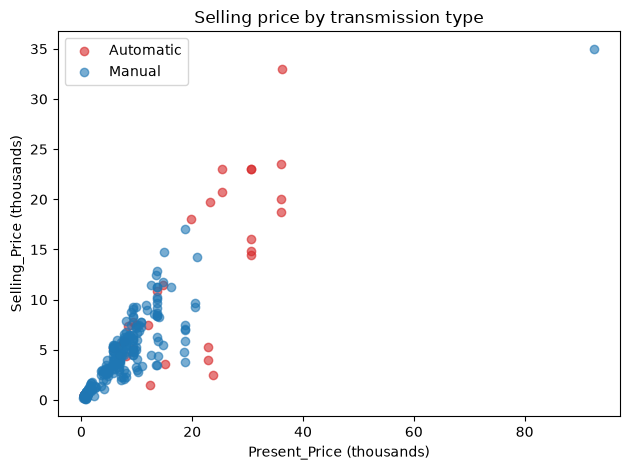

In [26]:
colours = {"Automatic": "tab:red", "Manual": "tab:blue"}

plt.figure()
for trans in ["Automatic", "Manual"]:
    subset = cars[cars["Transmission"] == trans]
    plt.scatter(subset["Present_Price"], subset["Selling_Price"], color=colours[trans], alpha=0.6, label=trans)
plt.xlabel("Present_Price (thousands)")
plt.ylabel("Selling_Price (thousands)")
plt.title("Selling price by transmission type")
plt.legend()
plt.tight_layout()
plt.show()

Automatic cars tend to have a higher selling price, and the slope may differ between the two groups. This suggests adding an interaction term.

### Interaction term

In a formula, `A * B` is a shortcut for `A + B + A:B`, where `A:B` is the interaction term. This automatically keeps both main effects in the model. The model is

$$Y=\beta_0+\beta_1X_1+\beta_2I(X_2=\text{Manual})+\beta_3X_1\times I(X_2=\text{Manual})+\varepsilon.$$

In [27]:
model_3 = smf.ols("Selling_Price ~ Present_Price * C(Transmission)", data=cars).fit()
print(model_3.summary())

                            OLS Regression Results                            
Dep. Variable:          Selling_Price   R-squared:                       0.790
Model:                            OLS   Adj. R-squared:                  0.788
Method:                 Least Squares   F-statistic:                     372.5
Date:                Tue, 20 Oct 2026   Prob (F-statistic):          2.66e-100
Time:                        00:47:32   Log-Likelihood:                -681.07
No. Observations:                 301   AIC:                             1370.
Df Residuals:                     297   BIC:                             1385.
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                                              coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------------------

The fitted lines for the two groups come from adding the relevant coefficients:

- Automatic: $\hat{Y}=\hat{\beta}_0+\hat{\beta}_1X_1$
- Manual: $\hat{Y}=(\hat{\beta}_0+\hat{\beta}_2)+(\hat{\beta}_1+\hat{\beta}_3)X_1$

In [28]:
p = model_3.params
int_auto = p["Intercept"]
slope_auto = p["Present_Price"]
int_manual = p["Intercept"]+p["C(Transmission)[T.Manual]"]
slope_manual = p["Present_Price"]+p["Present_Price:C(Transmission)[T.Manual]"]

print(f"Automatic: Y-hat = {round(int_auto, 3)} + {round(slope_auto, 3)}X")
print(f"Manual: Y-hat = {round(int_manual, 3)} + {round(slope_manual, 3)}X")

Automatic: Y-hat = 0.029 + 0.613X
Manual: Y-hat = 0.994 + 0.455X


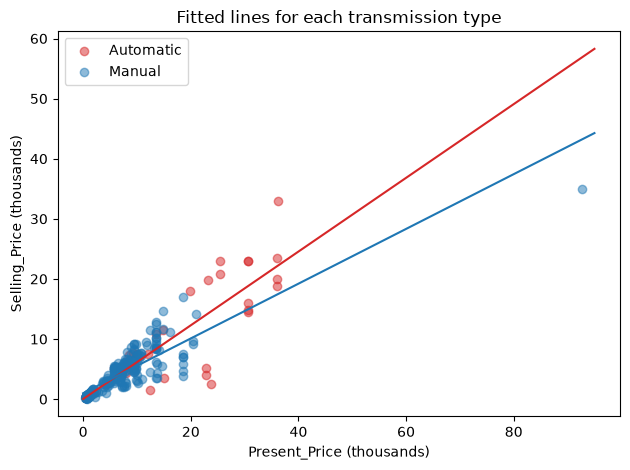

In [29]:
xs = np.linspace(0, 95, 100)

plt.figure()
for trans in ["Automatic", "Manual"]:
    subset = cars[cars["Transmission"] == trans]
    plt.scatter(subset["Present_Price"], subset["Selling_Price"], color=colours[trans], alpha=0.5, label=trans)
plt.plot(xs, int_auto+slope_auto*xs, color="tab:red")
plt.plot(xs, int_manual+slope_manual*xs, color="tab:blue")
plt.xlabel("Present_Price (thousands)")
plt.ylabel("Selling_Price (thousands)")
plt.title("Fitted lines for each transmission type")
plt.legend()
plt.tight_layout()
plt.show()

With the same present price $X_1$, a manual car's selling price differs from an automatic car's by $(0.965-0.158X_1)$ thousand dollars. The main effect of transmission has a $p$-value of 0.125, but the interaction term is highly significant ($p$-value $2.04\times10^{-5}$), so we keep both main effects together with the interaction.

### Checking the interaction model

We repeat the diagnostics for this model.

Number of outliers (|SR| > 3): 7
Influential points (Cook's distance > 1):
        Car_Name  Present_Price  Selling_Price Transmission
86  land cruiser           92.6           35.0       Manual
Cook's distance: 7.87


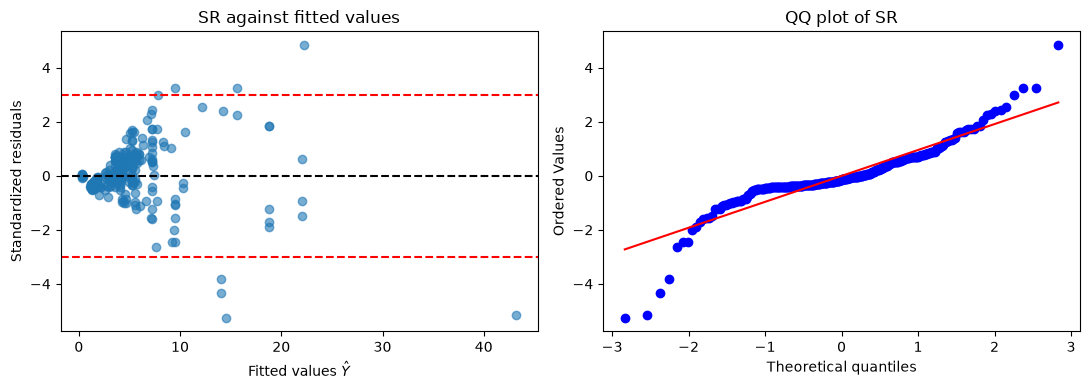

In [30]:
influence_3 = model_3.get_influence()
sr_3 = influence_3.resid_studentized_internal
cooks_3 = influence_3.cooks_distance[0]

print(f"Number of outliers (|SR| > 3): {np.sum(np.abs(sr_3) > 3)}")
print("Influential points (Cook's distance > 1):")
print(cars.loc[cooks_3 > 1, ["Car_Name", "Present_Price", "Selling_Price", "Transmission"]])
print(f"Cook's distance: {round(cooks_3.max(), 2)}")

fig, axes = plt.subplots(1, 2, figsize=(11,4))
axes[0].scatter(model_3.fittedvalues, sr_3, color="tab:blue", alpha=0.6)
for h in [0, 3, -3]:
    axes[0].axhline(h, color="black" if h == 0 else "red", linestyle="--")
axes[0].set_xlabel(r"Fitted values $\hat{Y}$")
axes[0].set_ylabel("Standardized residuals")
axes[0].set_title("SR against fitted values")
probplot(sr_3, plot=axes[1])
axes[1].set_title("QQ plot of SR")
plt.tight_layout()
plt.show()

The funnel shape and the tails of the QQ plot remain, there are 7 outliers, and the land cruiser is again a very influential point, with a Cook's distance of about 7.9. The model assumptions are not satisfied.

### Refitting without the influential point

One fix is to refit the model without the influential point. The function `.drop(index=86)` removes that row.

In [31]:
cars_dropped = cars.drop(index=86)
model_3b = smf.ols("Selling_Price ~ Present_Price * C(Transmission)", data=cars_dropped).fit()

print(model_3b.params.round(4))
print(model_3b.pvalues.round(4))

Intercept                                  0.0291
C(Transmission)[T.Manual]                  0.3147
Present_Price                              0.6132
Present_Price:C(Transmission)[T.Manual]   -0.0463
dtype: float64
Intercept                                  0.9593
C(Transmission)[T.Manual]                  0.6067
Present_Price                              0.0000
Present_Price:C(Transmission)[T.Manual]    0.2536
dtype: float64


Without the land cruiser, the interaction term is no longer significant ($p$-value 0.25), and its coefficient shrinks from $-0.158$ to $-0.046$. The land cruiser is the only manual car with a very high present price, so it alone was responsible for the different slope. This shows why influential points must be investigated before trusting a model's conclusions.

## A categorical variable with more than 2 categories

A categorical variable with $k$ categories needs $k-1$ indicator variables. `Fuel_Type` has 3 categories, so `C(Fuel_Type)` creates 2 indicators, with CNG (first alphabetically) as the baseline.

In [32]:
print(cars["Fuel_Type"].value_counts())

model_4 = smf.ols("Selling_Price ~ Present_Price + C(Fuel_Type)", data=cars).fit()
print(model_4.params.round(4))

Fuel_Type
Petrol    239
Diesel     60
CNG         2
Name: count, dtype: int64
Intercept                 0.0977
C(Fuel_Type)[T.Diesel]    2.7794
C(Fuel_Type)[T.Petrol]    0.5533
Present_Price             0.4680
dtype: float64


The coefficient of `C(Fuel_Type)[T.Diesel]` is the estimated difference in average selling price between a diesel car and a CNG car with the same present price, and similarly for petrol.

$\widehat{\text{Selling\_Price}}=0.0977+0.4680(\text{Present\_Price})+2.7794\,I(\text{Fuel\_Type}=\text{Diesel})+0.5533\,I(\text{Fuel\_Type}=\text{Petrol})$

There are only 2 CNG cars, so comparisons against CNG are not very precise. We can choose a different baseline with `Treatment`, for example Petrol, the most common category.

In [33]:
model_4b = smf.ols("Selling_Price ~ Present_Price + C(Fuel_Type, Treatment('Petrol'))", data=cars).fit()
print(model_4b.params.round(4))

Intercept                                      0.6510
C(Fuel_Type, Treatment('Petrol'))[T.CNG]      -0.5533
C(Fuel_Type, Treatment('Petrol'))[T.Diesel]    2.2261
Present_Price                                  0.4680
dtype: float64


$\widehat{\text{Selling\_Price}}=0.6510+0.4680(\text{Present\_Price})-0.5533\,I(\text{Fuel\_Type}=\text{CNG})+2.2261\,I(\text{Fuel\_Type}=\text{Diesel})$

The fitted model is the same, only written differently. For example, the diesel coefficient is now $2.7794-0.5533=2.2261$, the difference between diesel and petrol cars with the same present price.

| Fuel type | Fitted equation |
|---|---|
| CNG | $\widehat{\text{Selling\_Price}}=0.0977+0.4680(\text{Present\_Price})$ |
| Diesel | $\widehat{\text{Selling\_Price}}=2.8771+0.4680(\text{Present\_Price})$ |
| Petrol | $\widehat{\text{Selling\_Price}}=0.6510+0.4680(\text{Present\_Price})$ |

## Adding a higher-order term

To add $X^2$, we write `I(Present_Price**2)`. The `I(...)` tells the formula to calculate `Present_Price**2` as written, since `**` has a different meaning inside a formula. The model is still linear, because it is linear in the coefficients.

In [34]:
model_5 = smf.ols("Selling_Price ~ Present_Price + I(Present_Price**2)", data=cars).fit()
print(model_5.params)
print(model_5.pvalues)
print(f"Adjusted R-squared: {round(model_5.rsquared_adj, 4)}")

Intercept               -0.018304
Present_Price            0.664454
I(Present_Price ** 2)   -0.002933
dtype: float64
Intercept                9.287660e-01
Present_Price            6.107655e-76
I(Present_Price ** 2)    4.472114e-11
dtype: float64
Adjusted R-squared: 0.8022


$\widehat{\text{Selling\_Price}}=-0.0183+0.6645(\text{Present\_Price})-0.002933(\text{Present\_Price})^2$

The quadratic term is significant and the adjusted $R^2$ rises to 0.802. Because of the $X^2$ term, the effect of a one-unit increase in `Present_Price` is no longer constant: it depends on the starting value of $X$, as in the lecture's quadratic example.

## Transforming the response

A funnel shape suggests transforming the response. We can apply a function directly inside the formula, such as `np.log(Selling_Price)` or `np.sqrt(Selling_Price)`. 

In [35]:
model_6 = smf.ols("Selling_Price ~ Present_Price", data=cars).fit()
print(model_6.params)
print(model_6.pvalues)
print()

model_6a = smf.ols("np.sqrt(Selling_Price) ~ Present_Price", data=cars).fit()
print(model_6a.params)
print(model_6a.pvalues)
print()

model_6b = smf.ols("np.log(Selling_Price) ~ Present_Price", data=cars).fit()
print(model_6b.params)
print(model_6b.pvalues)

Intercept        0.718527
Present_Price    0.516849
dtype: float64
Intercept        1.461410e-04
Present_Price    3.602186e-98
dtype: float64

Intercept        1.117222
Present_Price    0.100756
dtype: float64
Intercept        1.739254e-73
Present_Price    7.900803e-77
dtype: float64

Intercept        0.119235
Present_Price    0.103838
dtype: float64
Intercept        8.687992e-02
Present_Price    1.098116e-46
dtype: float64


$$\widehat{\text{Selling\_Price}}=0.7185+0.5168(\text{Present\_Price})$$

$$\widehat{\sqrt{\text{Selling\_Price}}}=1.1172+0.1008(\text{Present\_Price})$$

$$\widehat{\ln(\text{Selling\_Price})}=0.1192+0.1038(\text{Present\_Price})$$

Take note that the interpretation also changes. For the square root model, $\hat{\beta}_1$ is the increase in $\sqrt{Y}$ (not $Y$) for every one-unit increase in $X$. We also cannot compare $R^2$ between models with different responses, since they measure the variation in different quantities.

| Response | Interpretation of the slope |
|---|---|
| $Y$ | For every one-unit increase in `Present_Price`, the average `Selling_Price` increases by 0.5168 |
| $\sqrt{Y}$ | For every one-unit increase in `Present_Price`, the average $\sqrt{\text{Selling\_Price}}$ increases by 0.1008 |
| $\ln(Y)$ | For every one-unit increase in `Present_Price`, the average $\ln(\text{Selling\_Price})$ increases by 0.1038 |

Let's compare the residuals against fitted values for the original response and two transformations.

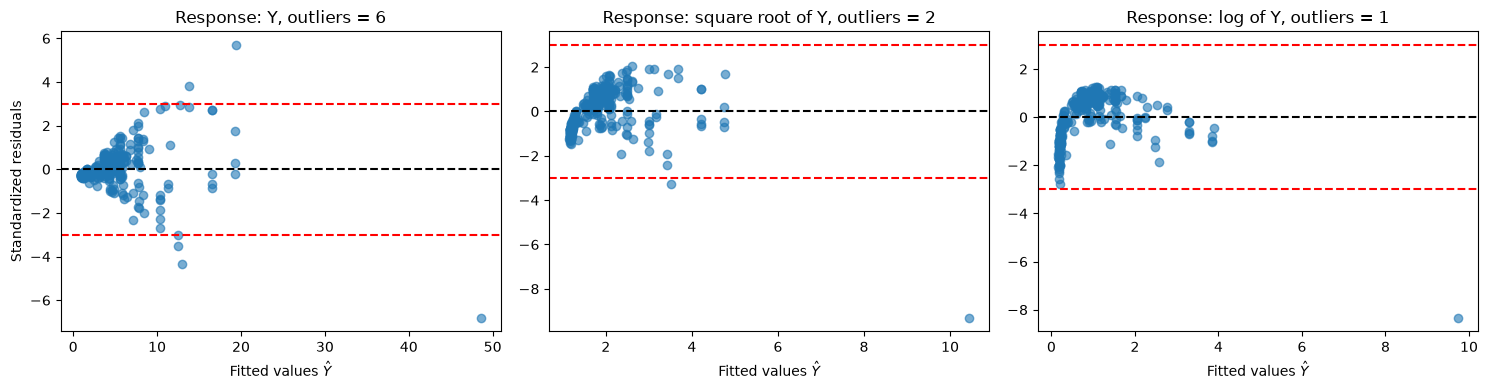

In [36]:
formulas = ["Selling_Price ~ Present_Price",
            "np.sqrt(Selling_Price) ~ Present_Price",
            "np.log(Selling_Price) ~ Present_Price"]
titles = ["Y", "square root of Y", "log of Y"]

fig, axes = plt.subplots(1, 3, figsize=(15,4))
for ax, formula, title in zip(axes, formulas, titles):
    m = smf.ols(formula, data=cars).fit()
    sr_m = m.get_influence().resid_studentized_internal
    ax.scatter(m.fittedvalues, sr_m, color="tab:blue", alpha=0.6)
    for h in [0, 3, -3]:
        ax.axhline(h, color="black" if h == 0 else "red", linestyle="--")
    ax.set_xlabel(r"Fitted values $\hat{Y}$")
    ax.set_title(f"Response: {title}, outliers = {np.sum(np.abs(sr_m) > 3)}")
axes[0].set_ylabel("Standardized residuals")
plt.tight_layout()
plt.show()

Both transformations reduce the funnel shape and the number of outliers, but they do not solve everything. The residuals for $\log(Y)$ now curve, which suggests the relationship with `Present_Price` is no longer linear, and the land cruiser (the point on the far right) stands out even more. In practice, fixing one problem can create another, so the diagnostics must be checked again after every change.

## Summary of Python tools in this topic

| Task | Code |
|---|---|
| Fit a model | `smf.ols("Y ~ X1 + X2", data=df).fit()` |
| Full output | `model.summary()` |
| Coefficients, standard errors | `model.params`, `model.bse` |
| $t$ values and $p$-values | `model.tvalues`, `model.pvalues` |
| CIs for the coefficients | `model.conf_int(alpha=0.05)` |
| Point estimate of the mean response | `model.predict(new_df)` |
| CI for the mean response | `model.get_prediction(new_df).summary_frame(alpha=0.05)` |
| Residual standard error | `np.sqrt(model.mse_resid)` |
| $F$-test | `model.fvalue`, `model.f_pvalue` |
| $R^2$, adjusted $R^2$ | `model.rsquared`, `model.rsquared_adj` |
| Standardized residuals | `model.get_influence().resid_studentized_internal` |
| Cook's distance | `model.get_influence().cooks_distance[0]` |
| Categorical variable | `C(var)`, or `C(var, Treatment('baseline'))` |
| Interaction term | `X1 * C(X2)` (main effects and interaction) |
| Higher-order term | `I(X**2)` |
| Transformed response | `np.log(Y)`, `np.sqrt(Y)`, `I(1/Y)` |